#_faruad_detection_project


In [3]:
import numpy as np

In [4]:
import pandas as pd

In [5]:
import os

In [6]:
(os.getcwd())
(os.listdir())

['.ipynb_checkpoints',
 'Fraud_Detection_System.ipynb',
 'paysim.csv',
 'result_faruad_detection.ipynb']

In [7]:
df = pd.read_csv("paysim.csv", nrows=5)
df

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [8]:
df.shape

(5, 11)

In [9]:
df.dtypes

step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            5 non-null      int64  
 1   type            5 non-null      object 
 2   amount          5 non-null      float64
 3   nameOrig        5 non-null      object 
 4   oldbalanceOrg   5 non-null      float64
 5   newbalanceOrig  5 non-null      float64
 6   nameDest        5 non-null      object 
 7   oldbalanceDest  5 non-null      float64
 8   newbalanceDest  5 non-null      float64
 9   isFraud         5 non-null      int64  
 10  isFlaggedFraud  5 non-null      int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 572.0+ bytes


In [11]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,5.0,5.000000,5.000000,5.000000,5.00000,5.0,5.000000,5.0
mean,1.0,4746.812000,46660.200000,41913.388000,4236.40000,0.0,0.400000,0.0
std,0.0,5564.259778,71131.405889,67416.975901,9472.87838,0.0,0.547723,0.0
min,1.0,181.000000,181.000000,0.000000,0.00000,0.0,0.000000,0.0
25%,1.0,181.000000,181.000000,0.000000,0.00000,0.0,0.000000,0.0
50%,1.0,1864.280000,21249.000000,19384.720000,0.00000,0.0,0.000000,0.0
75%,1.0,9839.640000,41554.000000,29885.860000,0.00000,0.0,1.000000,0.0
max,1.0,11668.140000,170136.000000,160296.360000,21182.00000,0.0,1.000000,0.0


In [12]:
df = pd.read_csv("paysim.csv")

print("Dataset shape:", df.shape)

Dataset shape: (6362620, 11)


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [14]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
(df["isFraud"].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [17]:
(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [18]:
df.groupby("type")["isFraud"].agg(["count", "sum"])

,count,sum
type,,
CASH_IN,1399284,0
CASH_OUT,2237500,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,532909,4097


In [19]:
fraud_rate = df.groupby("type")["isFraud"].mean() * 100

print(fraud_rate)

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64


In [20]:
(df.groupby("isFraud")["amount"].agg(["mean", "median", "max"]))

,mean,median,max
isFraud,,,
0,1.781970e+05,74684.72,92445516.64
1,1.467967e+06,441423.44,10000000.00


In [21]:
(df.groupby(["type", "isFraud"])["amount"]
      .agg(["mean", "median", "count"])
)

mean      median    count
type     isFraud                                   
CASH_IN  0        1.689202e+05  143427.710  1399284
CASH_OUT 0        1.739172e+05  146946.560  2233384
         1        1.455103e+06  435516.905     4116
DEBIT    0        5.483665e+03    3048.990    41432
PAYMENT  0        1.305760e+04    9482.190  2151495
TRANSFER 0        9.062290e+05  486521.910   528812
         1        1.480892e+06  445705.760     4097

In [22]:
df["balance_change"] = df["oldbalanceOrg"] - df["newbalanceOrig"]

df["balance_error"] = (
    df["balance_change"] - df["amount"]
).abs()

print(df[["amount", "balance_change", "balance_error"]].head())

     amount  balance_change  balance_error
0   9839.64         9839.64   1.455192e-11
1   1864.28         1864.28   1.136868e-12
2    181.00          181.00   0.000000e+00
3    181.00          181.00   0.000000e+00
4  11668.14        11668.14   0.000000e+00


In [23]:
(df.groupby("isFraud")["balance_error"]
      .agg(["mean", "median", "max"])
)

,mean,median,max
isFraud,,,
0,201338.558304,69049.31,92445516.64
1,10692.325265,0.00,10000000.00


In [24]:
(df.groupby(["type", "isFraud"])["balance_error"]
      .agg(["mean", "median", "count"])
)

mean        median    count
type     isFraud                                      
CASH_IN  0        337835.445783  2.868488e+05  1399284
CASH_OUT 0        147994.192850  1.198242e+05  2233384
         1          1306.125231  0.000000e+00     4116
DEBIT    0          1997.980422  2.955858e-12    41432
PAYMENT  0          6678.668482  3.807800e+02  2151495
TRANSFER 0        873050.622466  4.540331e+05   528812
         1         20122.054174  0.000000e+00     4097

In [25]:
(df.groupby(["type", "isFraud"])["balance_error"]
      .apply(lambda x: (x < 0.01).mean() * 100)
)

type      isFraud
CASH_IN   0           0.000000
CASH_OUT  0          10.883440
          1          99.416910
DEBIT     0          70.209017
PAYMENT   0          46.283305
TRANSFER  0           3.798136
          1          99.487430
Name: balance_error, dtype: float64

In [26]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = df["isFraud"]
y_pred = (df["balance_error"] < 0.01).astype(int)

(confusion_matrix(y_true, y_pred))
(classification_report(y_true, y_pred, zero_division=0))

'              precision    recall  f1-score   support\n\n           0       1.00      0.80      0.89   6354407\n           1       0.01      0.99      0.01      8213\n\n    accuracy                           0.80   6362620\n   macro avg       0.50      0.90      0.45   6362620\nweighted avg       1.00      0.80      0.89   6362620\n'

In [27]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

(cm)

array([[5066381, 1288026],
       [     45,    8168]])

In [28]:
mask = df["type"].isin(["CASH_OUT", "TRANSFER"])

y_true_filtered = df.loc[mask, "isFraud"]
y_pred_filtered = (
    (df.loc[mask, "balance_error"] < 0.01)
).astype(int)

(confusion_matrix(y_true_filtered, y_pred_filtered))
(classification_report(
    y_true_filtered, y_pred_filtered, zero_division=0
))

'              precision    recall  f1-score   support\n\n           0       1.00      0.90      0.95   2762196\n           1       0.03      0.99      0.06      8213\n\n    accuracy                           0.90   2770409\n   macro avg       0.52      0.95      0.50   2770409\nweighted avg       1.00      0.90      0.95   2770409\n'

In [29]:
df.groupby("isFraud")[
    ["amount", "oldbalanceOrg", "newbalanceOrig", "balance_change"]
].median()

,amount,oldbalanceOrg,newbalanceOrig,balance_change
isFraud,,,,
0,74684.72,14069.00,0.0,0.00
1,441423.44,438983.45,0.0,436317.49


In [30]:
selected_features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_error"
]

("Selected features:")
(selected_features)

("\nMissing values:")
(df[selected_features].isnull().sum())

step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
balance_error     0
dtype: int64

In [33]:
transaction_counts = df["type"].value_counts()

("Number of transactions by type:")
(transaction_counts)

("\nPercentage of each transaction type:")
((df["type"].value_counts(normalize=True) * 100).round(2))

type
CASH_OUT    35.17
PAYMENT     33.81
CASH_IN     21.99
TRANSFER     8.38
DEBIT        0.65
Name: proportion, dtype: float64

In [34]:
fraud_by_type = df.groupby("type")["isFraud"].agg(
    total_transactions="count",
    fraud_cases="sum",
    fraud_rate="mean"
)

fraud_by_type["fraud_rate"] = (
    fraud_by_type["fraud_rate"] * 100
).round(4)

(fraud_by_type.sort_values("fraud_cases", ascending=False))

,total_transactions,fraud_cases,fraud_rate
type,,,
CASH_OUT,2237500,4116,0.1840
TRANSFER,532909,4097,0.7688
CASH_IN,1399284,0,0.0000
DEBIT,41432,0,0.0000
PAYMENT,2151495,0,0.0000


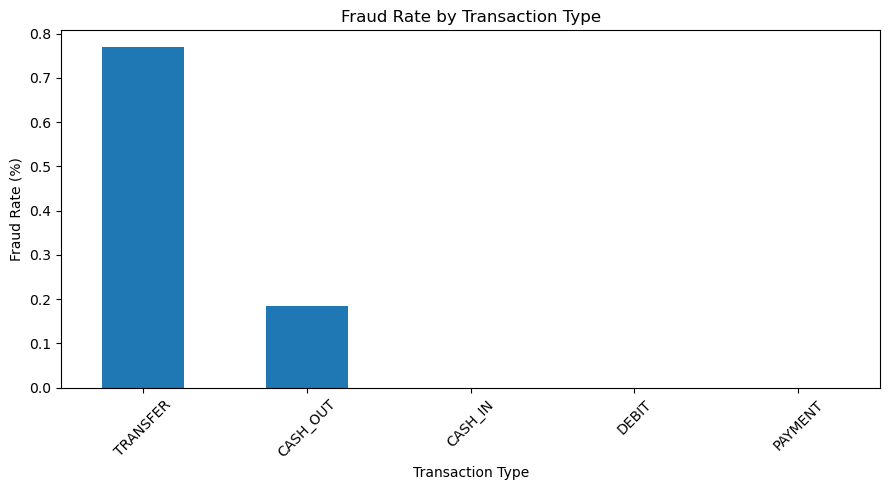

In [35]:
import matplotlib.pyplot as plt

fraud_rates = (
    df.groupby("type")["isFraud"].mean() * 100
).sort_values(ascending=False)

fraud_rates.plot(kind="bar", figsize=(9, 5))

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
("Transaction amount statistics by fraud label:")

(
    df.groupby("isFraud")["amount"].agg(
        ["count", "mean", "median", "min", "max"]
    ).round(2)
)

,count,mean,median,min,max
isFraud,,,,,
0,6354407,178197.04,74684.72,0.01,92445516.64
1,8213,1467967.30,441423.44,0.00,10000000.00


In [37]:
fraud_by_type = df.groupby("type")["isFraud"].agg(
    total_transactions="count",
    fraud_cases="sum",
    fraud_rate="mean"
)

fraud_by_type["fraud_rate"] = (
    fraud_by_type["fraud_rate"] * 100
).round(4)

print(fraud_by_type.sort_values("fraud_cases", ascending=False))

          total_transactions  fraud_cases  fraud_rate
type                                                 
CASH_OUT             2237500         4116      0.1840
TRANSFER              532909         4097      0.7688
CASH_IN              1399284            0      0.0000
DEBIT                  41432            0      0.0000
PAYMENT              2151495            0      0.0000


In [38]:
df["balance_change_orig"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["balance_change_dest"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

df["amount_to_balance_ratio"] = (
    df["amount"] /
    (df["oldbalanceOrg"] + 1)
)

print("New behavioral features:")
print(
    df[
        [
            "balance_change_orig",
            "balance_change_dest",
            "amount_to_balance_ratio"
        ]
    ].describe().round(3)
)

New behavioral features:
       balance_change_orig  balance_change_dest  amount_to_balance_ratio
count         6.362620e+06         6.362620e+06             6.362620e+06
mean         -2.123056e+04         1.242947e+05             7.067448e+04
std           1.466433e+05         8.129391e+05             5.084243e+05
min          -1.915268e+06        -1.306083e+07             0.000000e+00
25%           0.000000e+00         0.000000e+00             2.340000e-01
50%           0.000000e+00         0.000000e+00             6.454000e+00
75%           1.015043e+04         1.491054e+05             1.228776e+04
max           1.000000e+07         1.056878e+08             9.244552e+07


In [39]:
df["origin_balance_error"] = (
    df["balance_change_orig"] - df["amount"]
)

print("Origin balance error statistics:")
print(
    df["origin_balance_error"]
    .describe()
    .round(2)
)

print("\nTransactions with the largest absolute balance errors:")
print(
    df.loc[
        df["origin_balance_error"].abs().nlargest(10).index,
        [
            "type",
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "balance_change_orig",
            "origin_balance_error",
            "isFraud"
        ]
    ]
)

Origin balance error statistics:
count     6362620.00
mean      -201092.47
std        606650.46
min     -92445516.64
25%       -249641.09
50%        -68677.26
75%         -2954.23
max             0.01
Name: origin_balance_error, dtype: float64

Transactions with the largest absolute balance errors:
             type       amount  oldbalanceOrg  newbalanceOrig  \
3686583  TRANSFER  92445516.64            0.0             0.0   
4060598  TRANSFER  73823490.36            0.0             0.0   
4146397  TRANSFER  71172480.42            0.0             0.0   
3946920  TRANSFER  69886731.30            0.0             0.0   
3911956  TRANSFER  69337316.27            0.0             0.0   
3937152  TRANSFER  67500761.29            0.0             0.0   
4105338  TRANSFER  66761272.21            0.0             0.0   
3892529  TRANSFER  64234448.19            0.0             0.0   
3991638  TRANSFER  63847992.58            0.0             0.0   
4143801  TRANSFER  63294839.63            0.0     

In [40]:
df["insufficient_origin_balance"] = (
    df["amount"] > df["oldbalanceOrg"]
).astype(int)

print("Insufficient origin balance by fraud label:")

print(
    df.groupby("isFraud")["insufficient_origin_balance"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "total_transactions",
        "sum": "insufficient_balance_cases",
        "mean": "proportion"
    })
)

Insufficient origin balance by fraud label:
         total_transactions  insufficient_balance_cases  proportion
isFraud                                                            
0                   6354407                     4079051    0.641925
1                      8213                          29    0.003531


In [41]:
print("Origin balance error by fraud label:")

print(
    df.groupby("isFraud")["origin_balance_error"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Origin balance error by fraud label:
           count       mean    median          min   max
isFraud                                                 
0        6354407 -201338.56 -69049.31 -92445516.64  0.01
1           8213  -10692.33      0.00 -10000000.00  0.00


In [42]:
df["dest_balance_error"] = (
    df["balance_change_dest"] - df["amount"]
)

print("Destination balance error by fraud label:")

print(
    df.groupby("isFraud")["dest_balance_error"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Destination balance error by fraud label:
           count       mean   median          min          max
isFraud                                                       
0        6354407  -54692.23 -3500.68 -13191233.98  75885725.63
1           8213 -732509.30 -2231.46 -10000000.00   8875516.29


In [43]:
risk_features = [
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "balance_change_orig",
    "balance_change_dest",
    "origin_balance_error",
    "dest_balance_error"
]

print("Risk scoring features:")
print(risk_features)

print("\nMissing values in risk features:")
print(df[risk_features].isnull().sum())

print("\nData shape:")
print(df[risk_features].shape)

Risk scoring features:
['type', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balance_change_orig', 'balance_change_dest', 'origin_balance_error', 'dest_balance_error']

Missing values in risk features:
type                    0
amount                  0
oldbalanceOrg           0
newbalanceOrig          0
oldbalanceDest          0
newbalanceDest          0
balance_change_orig     0
balance_change_dest     0
origin_balance_error    0
dest_balance_error      0
dtype: int64

Data shape:
(6362620, 10)


In [45]:
type_risk_points = {
    "TRANSFER": 40,
    "CASH_OUT": 30,
    "PAYMENT": 10,
    "CASH_IN": 10,
    "DEBIT": 10
}

df["type_risk_score"] = (
    df["type"].map(type_risk_points).astype(int)
)

print("Risk score assigned by transaction type:")
print(
    df.groupby("type")["type_risk_score"]
    .first()
    .sort_values(ascending=False)
)

Risk score assigned by transaction type:
type
TRANSFER    40
CASH_OUT    30
CASH_IN     10
DEBIT       10
PAYMENT     10
Name: type_risk_score, dtype: int64


In [46]:
amount_quantiles = df["amount"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print("Transaction amount thresholds:")
print(amount_quantiles)

Transaction amount thresholds:
0.50    7.487194e+04
0.75    2.087215e+05
0.90    3.654233e+05
0.95    5.186342e+05
0.99    1.615979e+06
Name: amount, dtype: float64


In [48]:
df["amount_risk_score"] = 0

df.loc[df["amount"] > 208721.5, "amount_risk_score"] = 10
df.loc[df["amount"] > 365423.3, "amount_risk_score"] = 20
df.loc[df["amount"] > 518634.2, "amount_risk_score"] = 30


print(df["amount_risk_score"].value_counts().sort_index())

amount_risk_score
0     4771965
10     954393
20     318131
30     318131
Name: count, dtype: int64


In [49]:

df["risk_score"] = (
    df["type_risk_score"] + df["amount_risk_score"]
)


print("Minimum risk score:", df["risk_score"].min())
print("Maximum risk score:", df["risk_score"].max())


print(df["risk_score"].value_counts().sort_index())

Minimum risk score: 10
Maximum risk score: 70
risk_score
10    3146415
20     332911
30    1588669
40     686934
50     244524
60     109374
70     253793
Name: count, dtype: int64


In [50]:
risk_analysis = df.groupby("risk_score").agg(
    total_transactions=("isFraud", "count"),
    fraud_cases=("isFraud", "sum")
)

risk_analysis["fraud_rate_percent"] = (
    risk_analysis["fraud_cases"]
    / risk_analysis["total_transactions"] * 100
).round(4)

print(risk_analysis)

            total_transactions  fraud_cases  fraud_rate_percent
risk_score                                                     
10                     3146415            0              0.0000
20                      332911            0              0.0000
30                     1588669         1418              0.0893
40                      686934         1890              0.2751
50                      244524          799              0.3268
60                      109374         2196              2.0078
70                      253793         1910              0.7526


In [51]:
from sklearn.metrics import classification_report, confusion_matrix


df["predicted_fraud"] = (df["risk_score"] >= 40).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(df["isFraud"], df["predicted_fraud"]))

print("\nClassification Report:")
print(classification_report(
    df["isFraud"],
    df["predicted_fraud"],
    zero_division=0
))    

Confusion Matrix:
[[5066577 1287830]
 [   1418    6795]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89   6354407
           1       0.01      0.83      0.01      8213

    accuracy                           0.80   6362620
   macro avg       0.50      0.81      0.45   6362620
weighted avg       1.00      0.80      0.89   6362620



In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score


for threshold in [40, 50, 60, 70]:
    predictions = (df["risk_score"] >= threshold).astype(int)

    precision = precision_score(
        df["isFraud"], predictions, zero_division=0
    )
    recall = recall_score(
        df["isFraud"], predictions, zero_division=0
    )
    f1 = f1_score(
        df["isFraud"], predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1-score: {f1:.4f}"
    )

Threshold: 40 | Precision: 0.0052 | Recall: 0.8273 | F1-score: 0.0104
Threshold: 50 | Precision: 0.0081 | Recall: 0.5972 | F1-score: 0.0159
Threshold: 60 | Precision: 0.0113 | Recall: 0.4999 | F1-score: 0.0221
Threshold: 70 | Precision: 0.0075 | Recall: 0.2326 | F1-score: 0.0146


In [53]:
df["origin_error_abs"] = df["origin_balance_error"].abs()

print(
    df.groupby("isFraud")["origin_error_abs"]
    .median()
)

isFraud
0    69049.31
1        0.00
Name: origin_error_abs, dtype: float64


In [54]:
df["origin_error_abs"] = df["origin_balance_error"].abs()
df["dest_error_abs"] = df["dest_balance_error"].abs()


print("Origin balance error:")
print(df.groupby("isFraud")["origin_error_abs"].median())

print("\nDestination balance error:")
print(df.groupby("isFraud")["dest_error_abs"].median())

Origin balance error:
isFraud
0    69049.31
1        0.00
Name: origin_error_abs, dtype: float64

Destination balance error:
isFraud
0    5123.10
1    9511.69
Name: dest_error_abs, dtype: float64


In [55]:

dest_error_comparison = df.groupby("isFraud")["dest_error_abs"].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99]
)

print(dest_error_comparison)

isFraud      
0        0.50    5.123100e+03
         0.75    4.322716e+04
         0.90    3.163235e+05
         0.95    4.898710e+05
         0.99    8.763755e+05
1        0.50    9.511690e+03
         0.75    4.522947e+05
         0.90    2.078863e+06
         0.95    4.585021e+06
         0.99    1.000000e+07
Name: dest_error_abs, dtype: float64


In [56]:
from sklearn.metrics import confusion_matrix, classification_report


threshold = 489871

df["dest_error_prediction"] = (
    df["dest_error_abs"] > threshold
).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(df["isFraud"], df["dest_error_prediction"]))

print("\nClassification Report:")
print(classification_report(
    df["isFraud"],
    df["dest_error_prediction"],
    zero_division=0
))

Confusion Matrix:
[[6036686  317721]
 [   6235    1978]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   6354407
           1       0.01      0.24      0.01      8213

    accuracy                           0.95   6362620
   macro avg       0.50      0.60      0.49   6362620
weighted avg       1.00      0.95      0.97   6362620



In [57]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix


features = [
    "type",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
    "step"
]

X = df[features]
y = df["isFraud"]


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), [
            "amount",
            "oldbalanceOrg",
            "newbalanceOrig",
            "oldbalanceDest",
            "newbalanceDest",
            "step"
        ]),
        ("category", OneHotEncoder(handle_unknown="ignore"), ["type"])
    ]
)


model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])


model.fit(X_train, y_train)


y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Confusion Matrix:
[[1206133   64748]
 [     66    1577]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.95      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [58]:
from sklearn.metrics import precision_score, recall_score, f1_score


fraud_probabilities = model.predict_proba(X_test)[:, 1]


for threshold in [0.50, 0.70, 0.90, 0.95, 0.99]:
    predictions = (
        fraud_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_test, predictions, zero_division=0
    )
    recall = recall_score(
        y_test, predictions, zero_division=0
    )
    f1 = f1_score(
        y_test, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.0238 | Recall: 0.9598 | F1: 0.0464
Threshold: 0.70 | Precision: 0.0464 | Recall: 0.8941 | F1: 0.0882
Threshold: 0.90 | Precision: 0.1219 | Recall: 0.7705 | F1: 0.2104
Threshold: 0.95 | Precision: 0.1871 | Recall: 0.7042 | F1: 0.2957
Threshold: 0.99 | Precision: 0.3978 | Recall: 0.6080 | F1: 0.4810


In [59]:

print("Minimum step:", df["step"].min())
print("Maximum step:", df["step"].max())


print("\nTime boundaries:")
print(df["step"].quantile([0.70, 0.85]))


cut_1 = df["step"].quantile(0.70)
cut_2 = df["step"].quantile(0.85)

df["time_period"] = "test"
df.loc[df["step"] <= cut_2, "time_period"] = "validation"
df.loc[df["step"] <= cut_1, "time_period"] = "train"

print("\nTransactions and fraud cases by period:")
print(
    df.groupby("time_period", observed=True)["isFraud"]
    .agg(
        total_transactions="count",
        fraud_cases="sum"
    )
    .reindex(["train", "validation", "test"])
)

Minimum step: 1
Maximum step: 743

Time boundaries:
0.70    323.0
0.85    378.0
Name: step, dtype: float64

Transactions and fraud cases by period:
             total_transactions  fraud_cases
time_period                                 
train                   4463587         3643
validation               980416          564
test                     918617         4006


In [60]:

fraud_by_step = (
    df.groupby("step")["isFraud"]
    .agg(
        total_transactions="count",
        fraud_cases="sum"
    )
)

fraud_by_step["fraud_rate_percent"] = (
    fraud_by_step["fraud_cases"]
    / fraud_by_step["total_transactions"]
    * 100
)

print(fraud_by_step.describe())

print("\nSteps with the highest number of fraud cases:")
print(
    fraud_by_step.sort_values(
        "fraud_cases",
        ascending=False
    ).head(10)
)

       total_transactions  fraud_cases  fraud_rate_percent
count          743.000000   743.000000          743.000000
mean          8563.418573    11.053836           43.925264
std          13388.693217     4.998631           48.956185
min              2.000000     0.000000            0.000000
25%             12.000000     8.000000            0.074895
50%            529.000000    10.000000            1.915709
75%          12317.000000    14.000000          100.000000
max          51352.000000    40.000000          100.000000

Steps with the highest number of fraud cases:
      total_transactions  fraud_cases  fraud_rate_percent
step                                                     
212                34047           40            0.117485
523                   30           30          100.000000
249                23209           28            0.120643
425                   28           28          100.000000
501                   28           28          100.000000
387             

In [61]:


type_analysis = (
    df.groupby(["time_period", "type"], observed=True)["isFraud"]
    .agg(
        total_transactions="count",
        fraud_cases="sum"
    )
)

type_analysis["fraud_rate_percent"] = (
    type_analysis["fraud_cases"]
    / type_analysis["total_transactions"]
    * 100
)

print(type_analysis)

                      total_transactions  fraud_cases  fraud_rate_percent
time_period type                                                         
test        CASH_IN               204069            0            0.000000
            CASH_OUT              310302         2003            0.645500
            DEBIT                   6588            0            0.000000
            PAYMENT               317437            0            0.000000
            TRANSFER               80221         2003            2.496852
train       CASH_IN               977376            0            0.000000
            CASH_OUT             1582647         1831            0.115692
            DEBIT                  27764            0            0.000000
            PAYMENT              1506552            0            0.000000
            TRANSFER              369248         1812            0.490727
validation  CASH_IN               217839            0            0.000000
            CASH_OUT              3445

In [62]:

features = [
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "step"
]


train_df = df[df["time_period"] == "train"].copy()
val_df = df[df["time_period"] == "validation"].copy()
test_df = df[df["time_period"] == "test"].copy()

X_train = train_df[features]
y_train = train_df["isFraud"]

X_val = val_df[features]
y_val = val_df["isFraud"]

X_test = test_df[features]
y_test = test_df["isFraud"]

print("Train:", X_train.shape, "| Fraud cases:", y_train.sum())
print("Validation:", X_val.shape, "| Fraud cases:", y_val.sum())
print("Test:", X_test.shape, "| Fraud cases:", y_test.sum())

Train: (4463587, 5) | Fraud cases: 3643
Validation: (980416, 5) | Fraud cases: 564
Test: (918617, 5) | Fraud cases: 4006


In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)


numeric_features = [
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "step"
]

categorical_features = ["type"]


preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        (
            "category",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)


model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])


model.fit(X_train, y_train)


val_probabilities = model.predict_proba(X_val)[:, 1]
val_predictions = (val_probabilities >= 0.5).astype(int)

print("Confusion Matrix:")
print(confusion_matrix(y_val, val_predictions))

print("\nClassification Report:")
print(classification_report(
    y_val,
    val_predictions,
    zero_division=0
))

print(
    "Validation Average Precision:",
    round(average_precision_score(y_val, val_probabilities), 4)
)

Confusion Matrix:
[[935626  44226]
 [    71    493]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.95      0.98    979852
           1       0.01      0.87      0.02       564

    accuracy                           0.95    980416
   macro avg       0.51      0.91      0.50    980416
weighted avg       1.00      0.95      0.98    980416

Validation Average Precision: 0.1268


In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.50, 0.70, 0.90, 0.95, 0.99]:
    predictions = (val_probabilities >= threshold).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.0110 | Recall: 0.8741 | F1: 0.0218
Threshold: 0.70 | Precision: 0.0189 | Recall: 0.7819 | F1: 0.0368
Threshold: 0.90 | Precision: 0.0288 | Recall: 0.5248 | F1: 0.0546
Threshold: 0.95 | Precision: 0.0341 | Recall: 0.4379 | F1: 0.0632
Threshold: 0.99 | Precision: 0.0514 | Recall: 0.3121 | F1: 0.0883


In [65]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

numeric_features = [
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "step"
]

categorical_features = ["type"]


sample_df = (
    train_df.groupby("isFraud", group_keys=False)
    .apply(
        lambda group: group.sample(
            n=min(len(group), 100_000),
            random_state=42
        )
    )
)

X_sample = sample_df[features]
y_sample = sample_df["isFraud"]

preprocessor_tree = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        (
            "category",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1
                ))
            ]),
            categorical_features
        )
    ]
)

tree_model = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    ))
])

tree_model.fit(X_sample, y_sample)

tree_val_probabilities = tree_model.predict_proba(X_val)[:, 1]

from sklearn.metrics import average_precision_score

print(
    "Tree Validation Average Precision:",
    round(
        average_precision_score(y_val, tree_val_probabilities),
        4
    )
)

C:\Users\Fadak\AppData\Local\Temp\ipykernel_23488\970491702.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(
C:\Users\Fadak\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Fadak\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCore

Tree Validation Average Precision: 0.6631


In [66]:
from sklearn.metrics import precision_score, recall_score, f1_score

for threshold in [0.50, 0.70, 0.90, 0.95, 0.99]:
    predictions = (
        tree_val_probabilities >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, predictions, zero_division=0
    )
    recall = recall_score(
        y_val, predictions, zero_division=0
    )
    f1 = f1_score(
        y_val, predictions, zero_division=0
    )

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.4f} | "
        f"Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold: 0.50 | Precision: 0.3153 | Recall: 0.7961 | F1: 0.4517
Threshold: 0.70 | Precision: 0.4901 | Recall: 0.7057 | F1: 0.5785
Threshold: 0.90 | Precision: 0.7845 | Recall: 0.5550 | F1: 0.6501
Threshold: 0.95 | Precision: 0.8517 | Recall: 0.3972 | F1: 0.5417
Threshold: 0.99 | Precision: 0.8613 | Recall: 0.2642 | F1: 0.4043


In [67]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    average_precision_score
)

test_probabilities = tree_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= 0.90
).astype(int)

print("Test Average Precision:",
      round(average_precision_score(y_test, test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_predictions))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))

Test Average Precision: 0.8715

Confusion Matrix:
[[914501    110]
 [  1600   2406]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    914611
           1       0.96      0.60      0.74      4006

    accuracy                           1.00    918617
   macro avg       0.98      0.80      0.87    918617
weighted avg       1.00      1.00      1.00    918617



In [68]:
import pandas as pd


results = X_test.copy()

results["actual_fraud"] = y_test
results["model_score"] = test_probabilities
results["risk_score"] = (
    results["model_score"] * 100
).round(2)


results["prediction"] = (
    results["model_score"] >= 0.90
).astype(int)


def explain_transaction(row):
    reasons = []

    if row["type"] in ["TRANSFER", "CASH_OUT"]:
        reasons.append("نوع تراکنش در این داده با تقلب‌های مشاهده‌شده مرتبط است")

    if row["amount"] >= 200_000:
        reasons.append("مبلغ تراکنش بالا است")

    if row["oldbalanceOrg"] < row["amount"]:
        reasons.append("موجودی اولیه مبدأ کمتر از مبلغ تراکنش است")

    if not reasons:
        reasons.append("امتیاز مدل بالاست؛ بررسی بیشتر لازم است")

    return "؛ ".join(reasons)

results["explanation"] = results.apply(
    explain_transaction, axis=1
)


top_suspicious = results[
    results["prediction"] == 1
].sort_values(
    "risk_score", ascending=False
).head(10)

top_suspicious[
    [
        "type",
        "amount",
        "risk_score",
        "prediction",
        "explanation"
    ]
]

,type,amount,risk_score,prediction,explanation
6272939,CASH_OUT,10000000.00,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6038569,CASH_OUT,6669495.34,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6018798,CASH_OUT,2600970.32,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6065309,CASH_OUT,8991625.83,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6009604,CASH_OUT,10000000.00,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6283809,CASH_OUT,8730600.58,99.86,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362579,CASH_OUT,10000000.00,99.85,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362581,CASH_OUT,10000000.00,99.85,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362539,CASH_OUT,3912252.81,99.85,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
5467197,CASH_OUT,8317724.27,99.85,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...


In [69]:
top_suspicious[
    [
        "type",
        "amount",
        "risk_score",
        "prediction",
        "actual_fraud",
        "explanation"
    ]
]

,type,amount,risk_score,prediction,actual_fraud,explanation
6272939,CASH_OUT,10000000.00,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6038569,CASH_OUT,6669495.34,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6018798,CASH_OUT,2600970.32,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6065309,CASH_OUT,8991625.83,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6009604,CASH_OUT,10000000.00,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6283809,CASH_OUT,8730600.58,99.86,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362579,CASH_OUT,10000000.00,99.85,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362581,CASH_OUT,10000000.00,99.85,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
6362539,CASH_OUT,3912252.81,99.85,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...
5467197,CASH_OUT,8317724.27,99.85,1,1,نوع تراکنش در این داده با تقلب‌های مشاهده‌شده ...


In [70]:
output_columns = [
    "type",
    "amount",
    "risk_score",
    "prediction",
    "explanation"
]

results[output_columns].to_csv(
    "fraud_detection_results.csv",
    index=False
)

print("Fraud detection results saved successfully.")
print("Total transactions:", len(results))
print("Flagged transactions:", int(results["prediction"].sum()))

Fraud detection results saved successfully.
Total transactions: 918617
Flagged transactions: 2516


In [71]:
total_transactions = len(results)
flagged = results[results["prediction"] == 1]

print("Total transactions:", total_transactions)
print("Flagged transactions:", len(flagged))
print("Flagged rate (%):", round(
    len(flagged) / total_transactions * 100, 3
))

print("\nFraud among flagged:")
print(flagged["actual_fraud"].value_counts())

print("\nPrecision of flagged transactions (%):", round(
    flagged["actual_fraud"].mean() * 100, 2
))

Total transactions: 918617
Flagged transactions: 2516
Flagged rate (%): 0.274

Fraud among flagged:
actual_fraud
1    2406
0     110
Name: count, dtype: int64

Precision of flagged transactions (%): 95.63


In [72]:
import joblib

joblib.dump(tree_model, "fraud_detection_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [73]:
pip install streamlit

In [74]:
%%writefile app.py
import streamlit as st
import pandas as pd
import joblib

st.set_page_config(
    page_title="Fraud Detection System",
    page_icon="🔎",
    layout="centered"
)

model = joblib.load("fraud_detection_model.pkl")

st.title("Fraud Detection System")
st.write(
    "Analyze a transaction and estimate its fraud risk."
)

st.subheader("Transaction Details")

transaction_type = st.selectbox(
    "Transaction Type",
    ["CASH_OUT", "TRANSFER", "PAYMENT", "CASH_IN", "DEBIT"]
)

amount = st.number_input(
    "Transaction Amount",
    min_value=0.0,
    value=100000.0,
    step=1000.0
)

oldbalance_org = st.number_input(
    "Origin Balance Before Transaction",
    min_value=0.0,
    value=150000.0,
    step=1000.0
)

oldbalance_dest = st.number_input(
    "Destination Balance Before Transaction",
    min_value=0.0,
    value=0.0,
    step=1000.0
)

step = st.number_input(
    "Transaction Time Step",
    min_value=1,
    max_value=743,
    value=300
)

if st.button("Analyze Transaction"):
    transaction = pd.DataFrame([{
        "type": transaction_type,
        "amount": amount,
        "oldbalanceOrg": oldbalance_org,
        "oldbalanceDest": oldbalance_dest,
        "step": step
    }])

    score = model.predict_proba(transaction)[0, 1]
    risk_score = score * 100

    st.metric("Risk Score", f"{risk_score:.2f}/100")

    if score >= 0.90:
        st.error("High Risk: Transaction flagged for review.")
    else:
        st.success("Below Alert Threshold: No alert from this model.")

    reasons = []

    if transaction_type in ["TRANSFER", "CASH_OUT"]:
        reasons.append(
            "This transaction type was associated with fraud in the training dataset."
        )

    if amount >= 200000:
        reasons.append("The transaction amount is relatively high.")

    if oldbalance_org < amount:
        reasons.append(
            "The origin balance is lower than the transaction amount."
        )

    st.subheader("Review Notes")

    if reasons:
        for reason in reasons:
            st.write("- " + reason)
    else:
        st.write(
            "No simple rule-based warning was triggered. "
            "The model score should still be reviewed."
        )

    st.caption(
        "Prototype using synthetic PaySim data. "
        "Risk Score is a model score, not a calibrated fraud probability. "
        "Do not use as the sole basis for real financial decisions."
    )

Writing app.py


In [79]:
import os

print("App file:", os.path.exists("app.py"))
print("Model file:", os.path.exists("fraud_detection_model.pkl"))
print("Results file:", os.path.exists("fraud_detection_results.csv"))

App file: True
Model file: True
Results file: True
